In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
confusion_matrix, ConfusionMatrixDisplay, classification_report,
RocCurveDisplay
)

df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df.isnull().sum())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


## Inspection of the dataset
- **900 rows**: Each row represents one service ticket.
- **6 columns**: Five predictor variables and one target variable (escalated).
There are three columns with missing values:
- team_experience_years: 31 missing values
- priority: 18 missing values
- customer_tenure_months: 22 missing values
- **Total missing values**: 71

From our dataset, 79% of tickets are not escalated, while only 21% are escalated. A model could achieve a relatively high accuracy simply by predicting that every ticket is not escalated.

## Why this is classification
We are trying to predict the escalated column based on the characteristics of a service ticket. 
The target variable has two possible outcomes:
- **0** : The ticket was not escalated.
- **1** : The ticket was escalated.
Since we are predicting one of the two discrete categories rather than a continuous numerical value, this is a **binary classification problem**.

Our positive class is: *y = 1 (Escalated)*, since identifying tickets that require escalation is the primary objective.

In [4]:
X = df.drop("escalated", axis=1)
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [5]:
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training set shape: (675, 5)
Testing set shape: (225, 5)

Training target distribution:
escalated
0    0.792593
1    0.207407
Name: proportion, dtype: float64

Testing target distribution:
escalated
0    0.795556
1    0.204444
Name: proportion, dtype: float64


In [6]:
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [7]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(random_state=42))
])

lda_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LinearDiscriminantAnalysis())
])

knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=15))
])

In [8]:
models = {
    "Baseline": baseline_model,
    "Logistic Regression": logistic_model,
    "LDA": lda_model,
    "k-NN (k=15)": knn_model
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Baseline trained successfully.
Logistic Regression trained successfully.
LDA trained successfully.
k-NN (k=15) trained successfully.


In [9]:
predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)

In [10]:
results = []

for name, model in models.items():
    y_pred = predictions[name]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_prob)
    else:
        roc_auc = np.nan

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,LDA,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


## Comparison Interpretation
Logistic Regression and Linear Discriminant Analysis achieved the best overall results, both obtaining 82.22% accuracy, 75% precision, and 19.57% recall. Logistic Regression had a slightly higher ROC-AUC (0.8111) than LDA (0.8090), indicating marginally better discrimination between escalated and non-escalated tickets.

The k-NN model performed worse, with an F1-score of 0.1481 and recall of only 8.70%. The majority-class baseline achieved 79.56% accuracy but had zero recall because it predicted every ticket as non-escalated.

Although Logistic Regression and LDA performed relatively well in terms of accuracy and precision, their low recall indicates that they miss many genuinely escalated tickets. Therefore, accuracy alone is not sufficient for selecting the best model. Logistic Regression is the strongest candidate so far, but adjusting its classification threshold may improve its ability to identify escalated tickets.

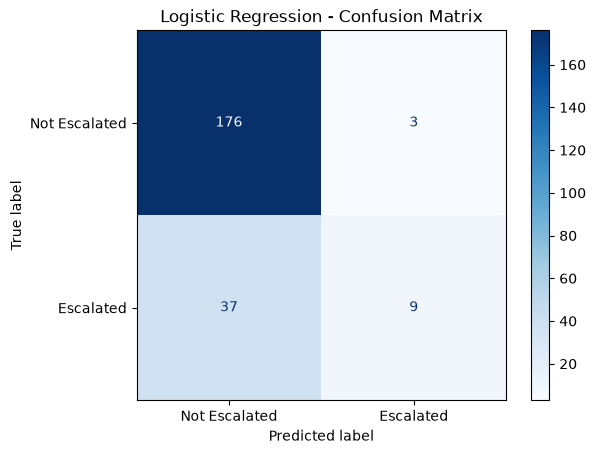

In [11]:
y_pred_log = logistic_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_log)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated", "Escalated"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

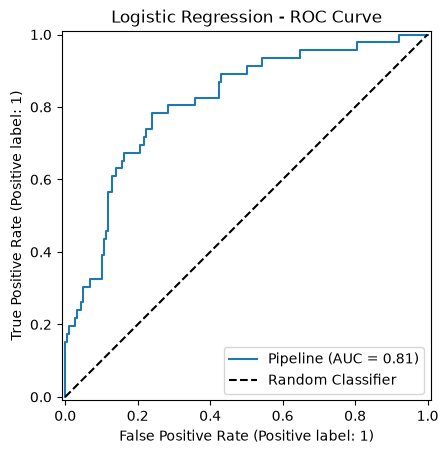

In [12]:
RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test
)

plt.title("Logistic Regression - ROC Curve")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.legend()
plt.show()

In [13]:
y_prob = logistic_model.predict_proba(X_test)[:, 1]

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(y_test, y_pred_threshold, zero_division=0)

    recall = recall_score(y_test, y_pred_threshold, zero_division=0)

    f1 = f1_score(y_test, y_pred_threshold, zero_division=0)

    cost = 5 * fn + fp

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FP": fp,
        "FN": fn,
        "Cost": cost
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


## Threshold Evaluation
The threshold evaluation shows that lowering the classification threshold increases recall while generally reducing precision. At a threshold of 0.20, the model achieved the highest recall (78.26%) and the lowest cost (98), although it produced 48 false positives. At 0.30, the model achieved the highest F1-score (0.5773), providing a more balanced trade-off between precision and recall. Since the cost function assigns five times more weight to false negatives than false positives, a threshold of 0.20 is preferred under the specified cost assumptions. This threshold reduces missed escalations from 37 at the default threshold of 0.50 to only 10. 

In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

knn_search = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ighbors=15))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': [5, 9, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inf

In [15]:
print("Best k:", knn_search.best_params_)
print("Best Cross-Validation F1:", knn_search.best_score_)

cv_results_df = pd.DataFrame(knn_search.cv_results_)

display(
    cv_results_df[
        [
            "param_classifier__n_neighbors",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").round(4)
)

Best k: {'classifier__n_neighbors': 5}
Best Cross-Validation F1: 0.24329611908559276


,param_classifier__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,5,0.2433,0.0946,1
1,9,0.1976,0.0652,2
2,15,0.1596,0.0655,3
3,21,0.1458,0.0564,4
4,31,0.1122,0.0397,5


In [16]:
best_knn = knn_search.best_estimator_

y_pred_best_knn = best_knn.predict(X_test)

print("Best k-NN Test Results")
print("Accuracy:", accuracy_score(y_test, y_pred_best_knn))
print("Precision:", precision_score(y_test, y_pred_best_knn, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_best_knn, zero_division=0))
print("F1:", f1_score(y_test, y_pred_best_knn, zero_division=0))

Best k-NN Test Results
Accuracy: 0.7911111111111111
Precision: 0.46153846153846156
Recall: 0.13043478260869565
F1: 0.2033898305084746


## Cross-validation results
The results show that **k=5** is the best K-NN configuration among the five values tested.
- With a smaller `k`, predictions depend on fewer nearby training examples.
- With a larger `k`, more neighbors influence each predictionx, potentially smoothing out local patterns, which makes k-NN less effective at identifying the minority class in our dataset.

Compared with the original k-NN model(k=15), tuning improved recall and F1, but k-NN still performs worse than Logistic Regression, whose default-threshold test F1 was 0.3103. Thus, Logistic Regression remains the strongest candidate based on the results so far.

## Model Recommendation for Ticket Escalation Prediction

Based on the experimental results, **Logistic Regression is the recommended model** for predicting whether a support ticket should be escalated. It achieved 82.22% accuracy, 75% precision, 19.57% recall, an F1-score of 0.3103, and a ROC-AUC of 0.8111 at the default threshold of 0.50. It performed slightly better than Linear Discriminant Analysis, which achieved the same accuracy, precision, recall, and F1-score but a marginally lower ROC-AUC of 0.8090. The k-NN model performed less effectively. Hyperparameter tuning improved its F1-score from 0.1481 with k=15 to 0.2034 with k=5, but it still did not outperform Logistic Regression. Cross-validation also identified k=5 as the best configuration, with an average F1-score of 0.2433.

The classification threshold significantly affects the model's performance. At the default threshold of 0.50, Logistic Regression achieved only 19.57% recall, meaning that it missed many genuinely escalated tickets. Lowering the threshold to 0.20 increased recall to 78.26%, reducing false negatives from 37 to 10. Although this produced 48 false positives and reduced precision to 42.86%, it achieved the lowest cost of 98 under the specified cost function (5 × FN + FP). Therefore, a threshold of 0.20 is recommended when minimizing the assumed escalation-related cost is the priority. However, a threshold of 0.30 achieved the highest F1-score of 0.5773 and may be preferable when a more balanced precision-recall trade-off is desired.

The experiments demonstrate that changing model configurations can significantly affect classification performance. For Logistic Regression, lowering the classification threshold increased recall from 19.57% at 0.50 to 78.26% at 0.20, while precision decreased from 75% to 42.86%. This illustrates how the threshold controls the trade-off between identifying more positive cases and generating more false positives. Similarly, tuning k-NN showed that the choice of the number of neighbors affects its ability to identify escalated tickets. Reducing k from 15 to 5 improved its test F1-score from 0.1481 to 0.2034 and recall from 8.70% to 13.04%. Cross-validation also confirmed that k=5 performed best among the tested values, with an average F1-score of 0.2433.

Overall, the results show that model selection alone does not determine classification performance; model configuration also plays an important role. Logistic Regression provided the strongest overall results among the evaluated models, while adjusting its classification threshold produced a substantial improvement in recall and F1-score. The k-NN experiments demonstrated that hyperparameter tuning can improve performance, although the tuned model still did not match Logistic Regression. Therefore, Logistic Regression with a threshold of 0.20 is the preferred configuration when minimizing the specified classification cost is the main objective, while a threshold of 0.30 is preferable when maximizing F1-score.

## Answers to the classification questions

### 1. Why is accuracy alone potentially misleading?

Accuracy measures the proportion of all predictions that are correct. For an imbalanced dataset such as the one we have worked on, simply predicting every ticket as non-escalated achieved 79.56% accuracy. However, this approach failed to identify any escalated tickets. This shows that a model can achieve high accuracy while performing poorly on the minority class, on the ones we want to identify.

### 2. Which classifier has the strongest recall? Which has the strongest precision/F1?

Based on the original model comparison at the default threshold of 0.50:
- **Strongest recall**: Logistic Regression and LDA tie at 19.57%.
- **Strongest precision**: Logistic Regression and LDA tie at 75%.
- **Strongest F1**: Logistic Regression and LDA tie at 0.3103.
Logistic Regression has a slightly higher ROC-AUC (0.8111) than LDA (0.8090), making it the stronger overall candidate between the two.

### 3. What changes when the threshold is lowered?

The threshold determines the minimum predicted probability required to classify a ticket as escalated. When the threshold decreases, more tickets are classified as escalated.
This generally causes:
- Recall to increase: More genuinely escalated tickets are identified.
- False negatives to decrease: Fewer escalated tickets are missed.
- False positives to increase: More non-escalated tickets are incorrectly flagged.
- Precision may decrease: A larger proportion of flagged tickets may be false alarms.

### 4. Which threshold minimizes \(5 \times FN + FP\) on the test set, and why might this estimate be optimistic if used repeatedly for tuning?

The threshold of 0.20 minimizes the cost, producing a total cost of 98. This threshold is preferred because false negatives are five times more expensive than false positives under the assignment's cost assumptions.

Why might this estimate be optimistic?

The test set is supposed to provide an independent evaluation of the model. However, if we repeatedly try different thresholds and select the one with the lowest test-set cost, we are indirectly tuning the model using the test data.

The selected threshold may perform particularly well on this specific test set but less well on new, unseen data. This is a form of overfitting to the test set.

A better approach is to select the threshold using validation data and evaluate the final configuration on the test set only once.

### 5. Explain prior, likelihood, posterior, and evidence using the ticket scenario.

These are the four main components of Bayes' theorem.
\[
P(E|x)=\frac{P(x|E)P(E)}{P(x)}
\]

Where \(E\) represents the event that a ticket is escalated, and \(x\) represents its observed features.
- Prior \(P(E)\): The probability that a ticket is escalated before considering its individual features. In our dataset, this is approximately 20.67%.
- Likelihood \(P(x|E)\): The probability of observing particular ticket characteristics, such as high complexity or urgent priority, given that the ticket is escalated.
- Evidence \(P(x)\): The overall probability of observing those ticket characteristics across all tickets, whether escalated or not.
- Posterior \(P(E|x)\): The probability that a particular ticket is escalated after considering its characteristics.
For example, before examining a ticket, we know that approximately 20.67% of tickets are escalated. If we then observe that a ticket has high complexity and urgent priority, we can use the likelihood of those features to update our belief about its escalation probability. The resulting posterior is the probability used to make the classification decision.

### 6. With posterior P(escalated|x) = 0.30, compare the expected cost of escalating and not escalating. Derive the cost-sensitive threshold.

- Probability of escalation: \(P(E|x)=0.30\)
- Probability of no escalation: \(1-0.30=0.70\)
- False-positive cost = 1
- False-negative cost = 5
We assume correct predictions have zero cost.

Option 1: Escalate the ticket

If we escalate:
- If the ticket is genuinely escalated, the decision is correct (cost 0).
- If it is not escalated, we make a false positive (cost 1).
Therefore:
\[
Cost(\text{escalate})=0.70 \times 1
\]

\[
\boxed{Cost(\text{escalate})=0.70}
\]

Option 2: Do not escalate the ticket

If we do not escalate:
- If the ticket is genuinely escalated, we make a false negative (cost 5).
- If it is not escalated, the decision is correct (cost 0).
Therefore:
$$ \text{Cost}(\text{not escalate}) = 0.30 \times 5 $$

$$ \boxed{\text{Cost}(\text{not escalate}) = 1.50} $$

Decision: We should escalate the ticket because its expected cost (0.70) is lower than not escalating it (1.50).
Deriving the cost-sensitive threshold
Let \(p=P(E|x)\).

The expected cost of escalating is:

$$ C_E = C_{FP}(1-p) $$

The expected cost of not escalating is:

$$ C_N = C_{FN}p $$

We should escalate when:

$$ C_{FP}(1-p) \leq C_{FN}p $$

Expanding:

$$ C_{FP} \leq p(C_{FP}+C_{FN}) $$

Therefore:

$$ \boxed{p \geq \frac{C_{FP}}{C_{FP}+C_{FN}}} $$

Substituting our costs:

$$ \text{Threshold} = \frac{1}{1+5} $$

$$ \boxed{\text{Threshold} = 0.1667} $$


This means that whenever the predicted probability of escalation is at least 16.67%, we should escalate the ticket to minimize the expected cost under these assumptions.

### 7. Which model would you recommend for deployment, and what further checks are required?

I would recommend Logistic Regression with a threshold of 0.20 as the strongest candidate. It achieved the highest ROC-AUC among the original models (0.8111), and lowering its threshold significantly improved recall from 19.57% to 78.26%. It also produced the lowest cost (98) under the specified cost function.

Before deployment, I would perform the following checks:
1. Validation: Select and verify the threshold using separate validation data rather than repeatedly tuning against the test set.
2. Generalization: Evaluate the model on additional real-world ticket data to determine whether its performance holds beyond the synthetic dataset.
3. Probability calibration: Check whether predicted probabilities accurately represent actual escalation frequencies, especially because the cost-sensitive decision rule relies on them.
4. Performance monitoring: Monitor precision, recall, F1, and false-positive/false-negative counts as new tickets arrive.
5. Fairness and human review: Check whether performance differs across relevant customer groups and ensure that predictions support human decisions rather than automatically determining ticket priority.
Overall, Logistic Regression with a carefully validated threshold is the strongest candidate based on the experiments conducted.